# Bank Marketing: Will a Client Subscribe? (PySpark MLlib)

Predicts whether a client subscribes to a term deposit after a phone campaign, using PySpark MLlib.

**Data:** *Bank Marketing* (Moro, Cortez and Rita, 2014), UCI Machine Learning Repository, [dataset 222](https://archive.ics.uci.edu/dataset/222/bank+marketing): `bank-full.csv`, 45,211 rows, 16 inputs. Licensed **CC BY 4.0**.

**Read before the results:** every model here uses `duration`, the length of the call. It is only known after the call ends, so these scores overstate what is possible when deciding whom to call. The GitHub repository's `analysis/baselines.py` measures models without it.

Code and README: [github.com/tahamohmadf19-dev/bank-marketing-classification](https://github.com/tahamohmadf19-dev/bank-marketing-classification)

## 1. Load the data
Set `BANK_DATA_PATH` to point at `bank-full.csv` elsewhere (on Kaggle, the attached dataset's path).

In [1]:
# Set BANK_DATA_PATH to use another location. See README for the download.
import os
DATA_PATH = os.environ.get("BANK_DATA_PATH", "data/bank-full.csv")

# -----------------------------
# BLOCK 1 – Spark Session + Load + Basic Cleaning
# -----------------------------
import os
from pyspark.sql import SparkSession

from pyspark.sql.functions import col, when, count, lit
from pyspark.sql import functions as F

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    Imputer,
)
from pyspark.ml.classification import (
    DecisionTreeClassifier,
    RandomForestClassifier,
    LinearSVC,
)
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator,
)

# 1.1 Spark session setup
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

spark = (
    SparkSession.builder
    .appName("BankMarketingClassification")
    .master("local[*]")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.host", "127.0.0.1")
    .getOrCreate()
)

# 1.2 Load dataset
df = spark.read.csv(DATA_PATH, header=True, sep=";", inferSchema=True)
print("Data loaded successfully")
df.show(5)
df.printSchema()

# 1.3 Replace literal "unknown" → "Not specified" في كل الأعمدة
# هذا يعادل: df = df.replace("unknown", "Not specified")
df = df.replace("unknown", "Not specified")


Data loaded successfully


+---+------------+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|age|         job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+------------+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
| 58|  management|married| tertiary|     no|   2143|    yes|  no|unknown|  5|  may|     261|       1|   -1|       0| unknown| no|
| 44|  technician| single|secondary|     no|     29|    yes|  no|unknown|  5|  may|     151|       1|   -1|       0| unknown| no|
| 33|entrepreneur|married|secondary|     no|      2|    yes| yes|unknown|  5|  may|      76|       1|   -1|       0| unknown| no|
| 47| blue-collar|married|  unknown|     no|   1506|    yes|  no|unknown|  5|  may|      92|       1|   -1|       0| unknown| no|
| 33|     unknown| single|  unknown|     no|      1|     no|  no|unknown|  5|  may|     19

## 2. Label and split
`randomSplit([0.6, 0.2, 0.2], seed)` gives train, validation and test sets. About 12% of clients subscribed, so accuracy alone is misleading.

Train count: 27294


Val count:   9047


Test count:  8870

Class distribution in TRAIN by y (no / yes):


+---+-----+
|  y|count|
+---+-----+
| no|24003|
|yes| 3291|
+---+-----+

Class distribution in TRAIN by label (0 / 1):


+-----+-----+
|label|count|
+-----+-----+
|    0|24003|
|    1| 3291|
+-----+-----+



+-----+-----+-------------------+
|label|count|         proportion|
+-----+-----+-------------------+
|    0|24003| 0.8794240492415916|
|    1| 3291|0.12057595075840845|
+-----+-----+-------------------+



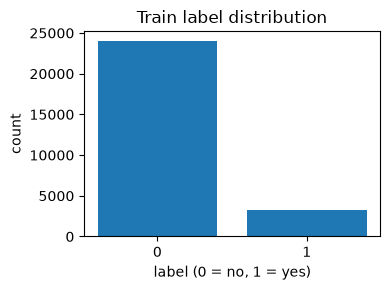

In [2]:
# -----------------------------
# BLOCK 2 – Label Encoding + Train/Val/Test Split + Class Dist
# -----------------------------

import matplotlib.pyplot as plt
from pyspark.sql.types import IntegerType

# Drop 'label' column if it exists from previous runs
if "label" in df.columns:
    df = df.drop("label")

# 2.1 تحويل y (no/yes) إلى label (0.0 / 1.0)
label_indexer = StringIndexer(
    inputCol="y",
    outputCol="label",
    handleInvalid="keep"
)
label_model = label_indexer.fit(df)
df = label_model.transform(df)

# Explicitly cast label to IntegerType to ensure binary (0 or 1) representation for LinearSVC
df = df.withColumn("label", F.col("label").cast(IntegerType()))

# 2.2 تقسيم Train / Validation / Test
train_df, temp_df = df.randomSplit([0.6, 0.4], seed=42)
val_df, test_df = temp_df.randomSplit([0.5, 0.5], seed=42)

print("Train count:", train_df.count())
print("Val count:  ", val_df.count())
print("Test count: ", test_df.count())

# 4.2 توزيع الكلاسات في TRAIN (بالكلمات + بالأرقام)
print("\nClass distribution in TRAIN by y (no / yes):")
train_df.groupBy("y").count().orderBy("y").show()

print("Class distribution in TRAIN by label (0 / 1):")
label_counts_df = train_df.groupBy("label").count().orderBy("label")
label_counts_df.show()

# 4.3 إضافة نسبة كل كلاس (اختياري)
total_train = train_df.count()
label_counts_df = label_counts_df.withColumn(
    "proportion",
    col("count") / F.lit(total_train)
)
label_counts_df.show()

# 4.4 تحويل إلى pandas للرسم
label_counts_pd = label_counts_df.toPandas()

# 4.5 رسم بسيط يوضح حجم كل كلاس في TRAIN
plt.figure(figsize=(4, 3))
plt.bar(label_counts_pd["label"], label_counts_pd["count"])
plt.xlabel("label (0 = no, 1 = yes)")
plt.ylabel("count")
plt.title("Train label distribution")
plt.xticks([0, 1])
plt.tight_layout()
plt.show()

## 3. Missing values and outliers
IQR bounds are computed on the **training split only** and then applied to validation and test.

In [3]:
# -----------------------------
# BLOCK 3 – Column Lists + Missing Values + Outlier Handling
# -----------------------------
from pyspark.sql.functions import col, when
from pyspark.sql import functions as F
from pyspark.ml.feature import Imputer

# 3.1 تعريف الأعمدة الرقمية والتصنيفية حسب Schema تبع bank-full.csv
numeric_cols = [
    "age",
    "balance",
    "day",
    "duration",
    "campaign",
    "pdays",
    "previous",
]

categorical_cols = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome",
]

label_col = "label"

# 3.2 فحص null لكل عمود في TRAIN
null_counts = train_df.select([
    F.count(F.when(col(c).isNull(), c)).alias(c)
    for c in train_df.columns
])

print("Null counts per column (TRAIN):")
null_counts.show(truncate=False)

# 3.3 تعويض القيم الناقصة في الأعمدة التصنيفية (categorical)
train_df = train_df.na.fill("Not specified", subset=categorical_cols)
val_df   = val_df.na.fill("Not specified", subset=categorical_cols)
test_df  = test_df.na.fill("Not specified", subset=categorical_cols)

# 3.4 حساب حدود الـ outliers لكل عمود رقمي في TRAIN باستخدام IQR
#     ثم عمل clipping على الأرقام في train/val/test
bounds = {}

for c in numeric_cols:
    # approxQuantile يرجّع [Q1, Q3]
    q1, q3 = train_df.approxQuantile(c, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    bounds[c] = (lower, upper)
    print(f"{c}: Q1={q1}, Q3={q3}, IQR={iqr}, lower={lower}, upper={upper}")

# 3.5 إنشاء أعمدة *_clipped بناءً على الحدود اللي حسبناها من TRAIN
for c in numeric_cols:
    lower, upper = bounds[c]
    new_col = c + "_clipped"

    train_df = train_df.withColumn(
        new_col,
        F.when(col(c) < lower, lower)
         .when(col(c) > upper, upper)
         .otherwise(col(c))
    )

    val_df = val_df.withColumn(
        new_col,
        F.when(col(c) < lower, lower)
         .when(col(c) > upper, upper)
         .otherwise(col(c))
    )

    test_df = test_df.withColumn(
        new_col,
        F.when(col(c) < lower, lower)
         .when(col(c) > upper, upper)
         .otherwise(col(c))
    )

# الآن رح نستخدم الأعمدة *_clipped في الـ Imputer بدل الأصلية
numeric_for_imputer = [c + "_clipped" for c in numeric_cols]

# 3.6 Imputer للأعمدة الرقمية (بعد الـ clipping)
imputer = Imputer(
    inputCols=numeric_for_imputer,
    outputCols=[c + "_imp" for c in numeric_cols]
).setStrategy("median")

numeric_imp_cols = [c + "_imp" for c in numeric_cols]


Null counts per column (TRAIN):


+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+-----+
|age|job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|y  |label|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+-----+
|0  |0  |0      |0        |0      |0      |0      |0   |0      |0  |0    |0       |0       |0    |0       |0       |0  |0    |
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+-----+



age: Q1=33.0, Q3=48.0, IQR=15.0, lower=10.5, upper=70.5


balance: Q1=72.0, Q3=1380.0, IQR=1308.0, lower=-1890.0, upper=3342.0


day: Q1=8.0, Q3=21.0, IQR=13.0, lower=-11.5, upper=40.5


duration: Q1=104.0, Q3=312.0, IQR=208.0, lower=-208.0, upper=624.0


campaign: Q1=1.0, Q3=3.0, IQR=2.0, lower=-2.0, upper=6.0


pdays: Q1=-1.0, Q3=-1.0, IQR=0.0, lower=-1.0, upper=-1.0


previous: Q1=0.0, Q3=0.0, IQR=0.0, lower=0.0, upper=0.0


## 4. Encode categorical features

In [4]:
# -----------------------------
# BLOCK 4 – Categorical Encoding + VectorAssembler
# -----------------------------

# 4.1 StringIndexer لكل عمود تصنيفي
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_idx",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

# 4.2 OneHotEncoder لكل عمود مصنّف indexed
encoders = [
    OneHotEncoder(
        inputCol=c + "_idx",
        outputCol=c + "_oh"
    )
    for c in categorical_cols
]

onehot_cols = [c + "_oh" for c in categorical_cols]

# 4.3 VectorAssembler لدمج كل الميزات في عمود واحد "features"
feature_cols = numeric_imp_cols + onehot_cols

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)


## 5. Class imbalance
The minority class is up-weighted with `weightCol`.

In [5]:
# -----------------------------
# BLOCK 5 – Imbalanced Data Handling (weightCol)
# -----------------------------

# 5.1 حساب عدد كل كلاس في TRAIN
class_counts = train_df.groupBy(label_col).count().collect()
counts_dict = {row[label_col]: row["count"] for row in class_counts}
print("Class counts in TRAIN:", counts_dict)

majority_label = max(counts_dict, key=counts_dict.get)
minority_label = min(counts_dict, key=counts_dict.get)
ratio = counts_dict[majority_label] / counts_dict[minority_label]

print(f"Majority label = {majority_label}, Minority label = {minority_label}, Ratio = {ratio:.2f}")

# 5.2 إضافة عمود weight على TRAIN:
# الكلاس النادر → weight = ratio
# الكلاس الأغلب → weight = 1.0
train_df = train_df.withColumn(
    "weight",
    when(col(label_col) == minority_label, ratio).otherwise(1.0)
)

# 5.3 على VAL و TEST نخلّي الوزن = 1.0 (للتقييم فقط)
val_df = val_df.withColumn("weight", lit(1.0))
test_df = test_df.withColumn("weight", lit(1.0))


Class counts in TRAIN: {1: 3291, 0: 24003}
Majority label = 0, Minority label = 1, Ratio = 7.29


In [6]:
# -----------------------------
# BLOCK 6 – Models (DT, RF, SVM) + Pipelines
# -----------------------------

# 6.1 تعريف الموديلات

# Decision Tree
dt_model_est = DecisionTreeClassifier(
    featuresCol="features",
    labelCol=label_col,
    weightCol="weight",   # يعالج ال imbalance
    maxDepth=10
)

# Random Forest
rf_model_est = RandomForestClassifier(
    featuresCol="features",
    labelCol=label_col,
    weightCol="weight",
    numTrees=200,
    maxDepth=10,
    seed=42
)

# Linear SVM (LinearSVC)
# بعض نسخ Spark لا تدعم weightCol في LinearSVC، لذلك ما حطيناه هنا لتجنب errors.
svm_model_est = LinearSVC(
    featuresCol="features",
    labelCol=label_col,
    maxIter=100,
    regParam=0.01
)

# 6.2 مراحل الـ preprocessing المشتركة
preprocess_stages = [imputer] + indexers + encoders + [assembler]

# 6.3 Pipelines لكل موديل
pipeline_dt = Pipeline(stages=preprocess_stages + [dt_model_est])
pipeline_rf = Pipeline(stages=preprocess_stages + [rf_model_est])
pipeline_svm = Pipeline(stages=preprocess_stages + [svm_model_est])


## 6. Compare models on validation

In [7]:
# -----------------------------
# BLOCK 7 – Train Models + Evaluate on Val/Test
# -----------------------------

# 7.1 تدريب الموديلات على TRAIN
print("\n=== Training Decision Tree model ===")
model_dt = pipeline_dt.fit(train_df)

print("\n=== Training Random Forest model ===")
model_rf = pipeline_rf.fit(train_df)

print("\n=== Training Linear SVM (LinearSVC) model ===")
model_svm = pipeline_svm.fit(train_df)

# 7.2 Evaluators
binary_eval = BinaryClassificationEvaluator(
    labelCol=label_col,
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

acc_eval = MulticlassClassificationEvaluator(
    labelCol=label_col,
    predictionCol="prediction",
    metricName="accuracy"
)

f1_eval = MulticlassClassificationEvaluator(
    labelCol=label_col,
    predictionCol="prediction",
    metricName="f1"
)

# 7.3 دالة تقييم لكل موديل على مجموعة بيانات محددة
def evaluate_on_dataframe(name, model, df_to_evaluate, df_name):
    print(f"\n================ {name} – {df_name} ================")
    predictions = model.transform(df_to_evaluate)
    auc = binary_eval.evaluate(predictions)
    acc = acc_eval.evaluate(predictions)
    f1  = f1_eval.evaluate(predictions)
    print(f"{df_name} AUC: {auc:.4f}")
    print(f"{df_name} ACC: {acc:.4f}")
    print(f"{df_name} F1 : {f1:.4f}")

# 7.4 تقييم النماذج الثلاثة على TRAIN و VALIDATION
# Decision Tree
evaluate_on_dataframe("Decision Tree", model_dt, train_df, "TRAIN")
evaluate_on_dataframe("Decision Tree", model_dt, val_df, "VALIDATION")

# Random Forest
evaluate_on_dataframe("Random Forest", model_rf, train_df, "TRAIN")
evaluate_on_dataframe("Random Forest", model_rf, val_df, "VALIDATION")

# Linear SVM
evaluate_on_dataframe("Linear SVM", model_svm, train_df, "TRAIN")
evaluate_on_dataframe("Linear SVM", model_svm, val_df, "VALIDATION")



=== Training Decision Tree model ===



=== Training Random Forest model ===



=== Training Linear SVM (LinearSVC) model ===



================ Decision Tree – TRAIN ================


TRAIN AUC: 0.7249
TRAIN ACC: 0.8587
TRAIN F1 : 0.8766

================ Decision Tree – VALIDATION ================


VALIDATION AUC: 0.6684
VALIDATION ACC: 0.8317
VALIDATION F1 : 0.8555

================ Random Forest – TRAIN ================


TRAIN AUC: 0.9477
TRAIN ACC: 0.8498
TRAIN F1 : 0.8699

================ Random Forest – VALIDATION ================


VALIDATION AUC: 0.9178
VALIDATION ACC: 0.8367
VALIDATION F1 : 0.8610

================ Linear SVM – TRAIN ================


TRAIN AUC: 0.9019
TRAIN ACC: 0.8897
TRAIN F1 : 0.8617

================ Linear SVM – VALIDATION ================


VALIDATION AUC: 0.9039
VALIDATION ACC: 0.8986
VALIDATION F1 : 0.8723


## 7. Tune the Random Forest on validation, then score the test set once

In [8]:
# -----------------------------
# BLOCK 7 – Tune Random Forest + Evaluate on Train/Val/Test
# -----------------------------

from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# إذا كنت مستخدم عمود label اسمه "label"
label_col = "label"

# 7.1 Evaluators
binary_eval = BinaryClassificationEvaluator(
    labelCol=label_col,
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

acc_eval = MulticlassClassificationEvaluator(
    labelCol=label_col,
    predictionCol="prediction",
    metricName="accuracy"
)

f1_eval = MulticlassClassificationEvaluator(
    labelCol=label_col,
    predictionCol="prediction",
    metricName="f1"
)

# 7.2 دالة تقييم على أي DataFrame
def evaluate_on_dataframe(name, model, df_to_evaluate, df_name):
    print(f"\n================ {name} – {df_name} ================")
    predictions = model.transform(df_to_evaluate)
    auc = binary_eval.evaluate(predictions)
    acc = acc_eval.evaluate(predictions)
    f1  = f1_eval.evaluate(predictions)
    print(f"{df_name} AUC: {auc:.4f}")
    print(f"{df_name} ACC: {acc:.4f}")
    print(f"{df_name} F1 : {f1:.4f}")
    return auc, acc, f1

# 7.3 Grid بسيط لتعديل خواص Random Forest
num_trees_list = [50, 100, 200]
max_depth_list = [5, 10, 15]

best_model = None
best_val_f1 = -1.0
best_params = None

for nt in num_trees_list:
    for md in max_depth_list:
        print(f"\n>>> Training Random Forest with numTrees={nt}, maxDepth={md}")

        rf_est = RandomForestClassifier(
            featuresCol="features",   # يفترض إن الـ VectorAssembler يخرج عمود اسمه "features"
            labelCol=label_col,
            numTrees=nt,
            maxDepth=md,
            seed=42
        )

        pipeline_rf = Pipeline(stages=preprocess_stages + [rf_est])

        # تدريب على TRAIN فقط
        model_rf = pipeline_rf.fit(train_df)

        # تقييم على VALIDATION فقط (نختار أفضل F1 عليه)
        _, _, val_f1 = evaluate_on_dataframe(
            f"Random Forest (trees={nt}, depth={md})",
            model_rf,
            val_df,
            "VALIDATION"
        )

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_model = model_rf
            best_params = (nt, md)

print("\n================ BEST Random Forest (by VALIDATION F1) ================")
print(f"Best numTrees: {best_params[0]}")
print(f"Best maxDepth: {best_params[1]}")
print(f"Best VALIDATION F1: {best_val_f1:.4f}")

# 7.4 تقييم الموديل الأفضل على TRAIN و TEST
evaluate_on_dataframe("Best Random Forest", best_model, train_df, "TRAIN")
evaluate_on_dataframe("Best Random Forest", best_model, test_df,  "TEST")



>>> Training Random Forest with numTrees=50, maxDepth=5



================ Random Forest (trees=50, depth=5) – VALIDATION ================


VALIDATION AUC: 0.9055
VALIDATION ACC: 0.9005
VALIDATION F1 : 0.8676

>>> Training Random Forest with numTrees=50, maxDepth=10



================ Random Forest (trees=50, depth=10) – VALIDATION ================


VALIDATION AUC: 0.9201
VALIDATION ACC: 0.9028
VALIDATION F1 : 0.8772

>>> Training Random Forest with numTrees=50, maxDepth=15



================ Random Forest (trees=50, depth=15) – VALIDATION ================


... (12 outputs left out)

VALIDATION AUC: 0.9295
VALIDATION ACC: 0.9059
VALIDATION F1 : 0.8905

================ BEST Random Forest (by VALIDATION F1) ================
Best numTrees: 100
Best maxDepth: 15
Best VALIDATION F1: 0.8928

================ Best Random Forest – TRAIN ================


TRAIN AUC: 0.9816
TRAIN ACC: 0.9520
TRAIN F1 : 0.9474

================ Best Random Forest – TEST ================


TEST AUC: 0.9268
TEST ACC: 0.9051
TEST F1 : 0.8919


(0.9267840621719434, 0.9050732807215333, 0.8919293552961156)

## Results and limitations

Saved outputs of the clean rerun (Spark, seeded `randomSplit`):

| Model | Split | AUC | Accuracy | Weighted F1 |
|---|---|---:|---:|---:|
| Decision Tree | validation | 0.668 | 0.832 | 0.856 |
| Linear SVM | validation | 0.904 | 0.899 | 0.872 |
| Random Forest, tuned (100 trees, depth 15) | validation | 0.929 | 0.907 | 0.893 |
| Random Forest, tuned | **test** | **0.927** | **0.905** | **0.892** |

- **Accuracy needs a baseline.** Always answering "no" already scores 0.883, because only about 12% subscribe.
- **Weighted F1 is dominated by the "no" class.** In the repository's baselines (80/20 stratified split), F1 for the "yes" class is only about 0.44 *with* `duration`.
- **Without `duration`** (the honest pre-call setting), the repository's baselines reach ROC-AUC 0.80 and yes-class F1 0.31 with a Random Forest.
- The train AUC of the tuned forest (0.982) against test (0.927) shows some overfitting.